<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW3.3/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 3.3 Optimization and Gradient Descent
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers
A local minimizer of a function $f$ is a point $x_0$ where there exists a $\delta > 0$ such that for all $x$ within a distance $\delta$ to $x_0$, $f(x)\ge f(x_0)$. If $f(x)$ is twice continuously differentiable, we can find these local minimizers by finding where $f'(x)=0$ and $f''(x)>0$.

x=-1: f'(x)=0.0, f''(x)=4.5, f(x)=-0.625
x=0: f'(x)=0.0, f''(x)=-3.0, f(x)=0.0
x=2: f'(x)=0.0, f''(x)=9.0, f(x)=-4.0


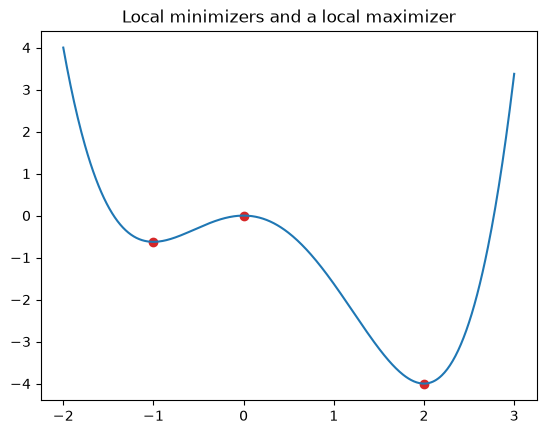

In [2]:
def f(x):
    return -((12-3*x**2+4*x)*x**2)/8

def fp(x):
    return -3*x*(2-x**2+x)/2

def fpp(x):
    return -3*(2-3*x**2+2*x)/2

critical_points = np.array([-1, 0, 2])
for c in critical_points:
    print(f"x={c}: f'(x)={fp(c)}, f''(x)={fpp(c)}, f(x)={f(c)}")

x = np.linspace(-2, 3, 500)
plt.plot(x, f(x))
plt.scatter(critical_points, f(critical_points), color="tab:red")
plt.title("Local minimizers and a local maximizer")
plt.show()

As you can see, this function has 2 local minimizers, x=-1 and x=2, because at both of these values $f'(x)=0$ and $f''(x)>0$. The point x=0 is not a local minimizer as $f''(x)<0$ and is rather a local maximizer, which is larger than other points in a small neighborhood.
## 3.3.2 Convexity and Global Minimizers
A function $g$ is convex if for all pairs of points $x$ and $y$ and all values $\alpha$ on the interval [0,1], $g((1-\alpha)x+\alpha y)\le(1-\alpha)g(x)+\alpha g(y)$. It can be shown that if $g$ is twice continuously differentiable and for all values of x, $g''(x)>0$, than $g$ is convex. This is useful because it means that for any value of x where $g'(x)=0$, x is a local minimizer of $g$ and it can be shown that any local minimizer of a convex function is also a global minimizer.

x=1: f'(x)=0.0, f''(x)=1.0


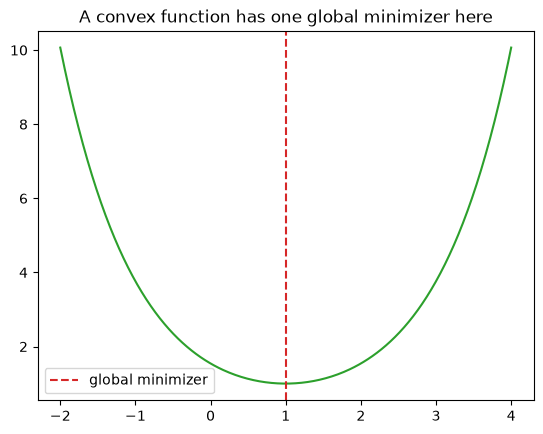

In [3]:
def g(x):
    return np.cosh(x-1)

def gp(x):
    return np.sinh(x-1)

print(f"x=1: f'(x)={gp(1)}, f''(x)={g(1)}")
x = np.linspace(-2, 4, 300)
plt.plot(x, g(x), color="tab:green")
plt.axvline(1, color="tab:red", linestyle="--", label="global minimizer")
plt.title("A convex function has one global minimizer here")
plt.legend()
plt.show()


As you can see with $g(x)=\cosh(x-1)$ (which is convex because $g''(x)=\cosh(x-1)$ and $\cosh(x)>0$ for all x) the value where $g'(x)=\sinh(x-1)=0$, x=1 is the global minimizer of $g$ as no other value of $g$ is less than 1 (the value of $g$ at x=1).
## 3.3.3 Gradient Descent
Given a differentiable function $g$, we can use gradient descent to find a local minimum of $g$. Steepest descent is a method where we follow the negative gradient of $g$, $-\nabla g$ (or $-g'$ in the 1D case) which is the direction in which $g$ decreases to find a new smaller value with each iteration. This method is formulated as $x_{n+1}=x_n-\alpha _n\nabla g(x_n)$ where $\alpha _n$ is a value greater than 0 that minimizes $x_n-\alpha _n\nabla g(x_n)$. For the purposes of gradient descent, we select a learning rate for our step size rather than the perfect $\alpha _n$ as finding the optimal value for $\alpha _n$ is itself an optimization problem.

Final x = 0.9998123141158839
Final objective = 1.0000000176129955


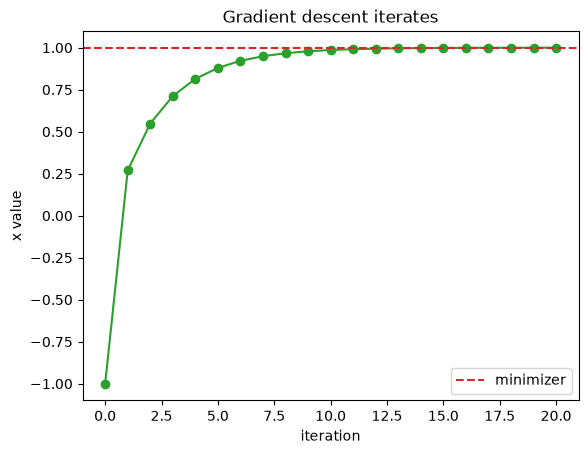

In [4]:
learning_rate = 0.35
current = -1.0
path = [current]
for _ in range(20):
    current = current - learning_rate * gp(current)
    path.append(current)

path = np.array(path)
print("Final x =", path[-1])
print("Final objective =", g(path[-1]))

plt.plot(path, marker="o", color="tab:green")
plt.axhline(1, color="tab:red", linestyle="--", label="minimizer")
plt.xlabel("iteration")
plt.ylabel("x value")
plt.title("Gradient descent iterates")
plt.legend()
plt.show()

As you can see above, gradient descent with a learning rate of 0.35 quickly approached 1, which is the global minimizer, and only local minimizer for $g(x)=\cosh(x-1)$, indicating that at least for hyperbolic cosine, gradient descent is an effective numerical method for finding local minimizers.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.